# REFIT washing-machine NILM — complete pipeline (one notebook)

**How to run (phone or laptop):** `Runtime → Change runtime type → T4 GPU` → `Runtime → Run all`. Nothing needs to be downloaded or unzipped by hand — the notebook downloads the official REFIT archives itself, extracts only the files it needs, and writes all results to Google Drive (`MyDrive/refit_outputs/`).

| Part | Data | What happens |
|---|---|---|
| A | — | download + extract REFIT (raw House 1 files, clean files of the selected houses, README) |
| **1** | **raw House 1** | audit (ordering, duplicates, intervals, gaps, impossible values) → cleaning → 1-min → before/after plots |
| **2** | **clean, 4–6 houses** | quality table, washing-machine cycle rule, usage by hour/weekday, cross-house comparison, 24-h trace, cycles |
| **3** | **clean, same houses** | leave-one-house-out: baselines → LightGBM → gated LightGBM + cycle rule → gated CNN → ensemble; metrics, plots, failure analysis |
| Z | — | auto-generated markdown tables for DATA.md / RESULTS.md + zip of all outputs |

Expected runtime with defaults (6 houses × 365 days, T4 GPU): roughly 60–90 min. Folds are cached on Drive — if Colab disconnects, just **Run all** again and finished folds are skipped.

## 0. Setup & configuration

In [1]:
import os, sys, re, gc, glob, json, time, shutil, pickle, subprocess, warnings
warnings.filterwarnings('ignore')
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
for pkg in ('lightgbm', 'py7zr', 'tabulate'):
    try:
        __import__(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

Mounted at /content/drive


In [2]:
# ===================== CONFIG — the only cell you may want to edit =====================
OUT_ROOT    = os.environ.get('REFIT_OUT', '/content/drive/MyDrive/refit_outputs' if IN_COLAB else './refit_outputs')
DATA_DIR    = os.environ.get('REFIT_DATA_DIR', '/content/refit_data' if IN_COLAB else './refit_data')   # extracted CSVs (local disk, fast)
ARCHIVE_DIR = os.environ.get('REFIT_ARCHIVE_DIR', '/content/refit_archives' if IN_COLAB else './refit_archives')  # downloaded .7z
# Folders searched first for an already-downloaded archive / README (so you never download twice):
SEARCH_DIRS = [ARCHIVE_DIR, '/content/drive/MyDrive/refit', '/content/drive/MyDrive']

RUN_PART1   = True       # Part 1 on raw House 1 (downloads the raw archive as well)
HOUSES      = 'auto'     # 'auto' = houses whose README lists a "Washing Machine"; or e.g. [1, 2, 5, 7, 8, 15]
MAX_HOUSES  = int(os.environ.get('REFIT_MAX_HOUSES', 6))          # houses used for EDA and as unseen test houses (≥ 4 required)
EXTRA_TRAIN_HOUSES = int(os.environ.get('REFIT_EXTRA', 3))   # further eligible houses used ONLY for training (more variety → better generalisation)
MAX_DAYS_PER_HOUSE = 365 # first N days per house (runtime); None = full ~2-year period
TARGET_OVERRIDE = {}     # e.g. {9: 'Appliance3'} if the README parse is wrong for a house
USE_CNN     = os.environ.get('REFIT_USE_CNN', 'auto')   # 'auto' = only with a GPU
CNN_EPOCHS  = int(os.environ.get('REFIT_CNN_EPOCHS', 12))

URL_CLEAN  = 'https://pureportal.strath.ac.uk/files/62090184/CLEAN_REFIT_081116.7z'
URL_RAW    = 'https://pureportal.strath.ac.uk/files/62090177/REFIT_RAW_081116.7z'
URL_README = 'https://pure.strath.ac.uk/ws/portalfiles/portal/62090183/CLEAN_READ_ME_081116.txt'

# Part 1 cleaning thresholds
RESAMPLE_RULE = '1min'
AGG_MAX_W  = 20000   # UK domestic supply 60–100 A @ 230 V ≈ 14–23 kW
APPL_MAX_W = 4000    # plug monitor rating (13 A ≈ 3 kW); same limit as the official clean release
# =========================================================================================
for d in (OUT_ROOT, DATA_DIR, ARCHIVE_DIR): os.makedirs(d, exist_ok=True)
print('outputs →', OUT_ROOT)

outputs → /content/drive/MyDrive/refit_outputs


## 1. Helper library
Cleaning, cycle rule, features, models and metrics — identical for every house. Key rules: clean-data minutes with **0 W aggregate are missing** (the official cleaning writes gaps > 2 min as 0 W); gaps ≤ 5 min interpolated, longer ones excluded; cycle = > 20 W, pauses ≤ 10 min merged, ≥ 15 min, ≥ 0.05 kWh; features from the **aggregate only**.

In [3]:
# ---------------- helper library (embedded in the notebook) ----------------
import os, re, time, json, warnings
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, precision_score, recall_score, f1_score

TZ = 'Europe/London'
ON_THRESHOLD_W = 20
CYCLE_MAX_GAP_MIN = 10
CYCLE_MIN_DUR_MIN = 15
CYCLE_MIN_ENERGY_KWH = 0.05
MAX_FILL_GAP_MIN = 5
SEED = 42


# ---------- README ----------
def _parse_items(line):
    """'0.Aggregate, 1.Fridge, 2.Freezer(1), ...' → {'Appliance1': 'Fridge', 'Appliance2': 'Freezer(1)', ...}"""
    out = {}
    for item in line.split(','):
        m = re.match(r'\s*(\d)\s*[\.\):=-]\s*([A-Za-z].*?)\s*$', item)
        if m and 1 <= int(m.group(1)) <= 9 and f'Appliance{int(m.group(1))}' not in out:
            out[f'Appliance{int(m.group(1))}'] = m.group(2).strip()
    return out


def parse_readme(readme_path):
    """{house_id: {'Appliance1': 'Fridge', ...}} from the REFIT README.

    Uses the appliance list line of each house block (the line that starts with '0.Aggregate'),
    so dates or notes elsewhere in the block cannot overwrite a channel name."""
    try:
        txt = open(readme_path, encoding='latin-1').read()
    except FileNotFoundError:
        return {}
    out = {}
    for m in re.finditer(r'House\s*(\d+)\b(.*?)(?=House\s*\d+\b|\Z)', txt, flags=re.S | re.I):
        h, block = int(m.group(1)), m.group(2)
        if h in out:
            continue
        lines = [l for l in block.splitlines() if re.search(r'\b0\s*\.\s*Aggregate', l, re.I)]
        mapping = _parse_items(' , '.join(lines)) if lines else {}
        if len(mapping) < 5:                                   # fallback: any "n.Name" pairs, first wins
            mapping = _parse_items(','.join(re.findall(r'\d\s*\.\s*[A-Za-z][^,\n]*', block)))
        if len(mapping) >= 5:
            out[h] = mapping
    return out


def find_wm_column(mapping):
    for pat in (r'washing\s*machine', r'washer'):
        c = [k for k, v in mapping.items() if re.search(pat, v, re.I)]
        if c:
            return c[0]
    return None


def washing_channels(mapping):
    """All channels that are a washing appliance (washing machine, washer dryer, ...)."""
    return [k for k, v in mapping.items() if re.search(r'wash', v, re.I) and not re.search(r'dish', v, re.I)]


# ---------- loading & cleaning (official CLEAN files) ----------
def fill_short_gaps(s, max_len):
    isna = s.isna()
    run_len = isna.groupby((~isna).cumsum()).transform('sum')
    short = isna & (run_len <= max_len)
    out = s.copy()
    out[short] = s.interpolate(method='time', limit_area='inside')[short]
    return out


def read_clean_columns(paths, cols):
    """Read the given power columns from one or several clean CSVs of the same house
    (e.g. a house split over two files), indexed by UTC time, sorted, duplicates dropped."""
    paths = [paths] if isinstance(paths, str) else list(paths)
    parts = []
    for p in paths:
        head = pd.read_csv(p, nrows=2)
        tcol = 'Unix' if 'Unix' in head.columns else head.columns[1]
        d = pd.read_csv(p, usecols=[tcol, *cols], dtype={c: 'float32' for c in cols})
        d.index = pd.to_datetime(pd.to_numeric(d.pop(tcol), errors='coerce'), unit='s', utc=True)
        parts.append(d[d.index.notna()])
    df = pd.concat(parts).sort_index(kind='mergesort')
    return df[~df.index.duplicated(keep='first')]


def load_clean_house(path, wm_col, max_days=None):
    """Official clean CSV(s) → 1-min frame with columns aggregate, wm, outage.

    The official cleaning writes gaps > 2 min as 0 W in every channel, so a minute whose
    aggregate is 0 W (a real home never draws exactly 0 W) is treated as an outage.
    max_days keeps only the first N days (runtime control).
    """
    df = read_clean_columns(path, ['Aggregate', wm_col])
    if max_days:
        df = df[df.index < df.index.min() + pd.Timedelta(days=max_days)]
    df.loc[df['Aggregate'] <= 0, ['Aggregate', wm_col]] = np.nan          # zero-filled gaps → missing
    m = df[['Aggregate', wm_col]].resample('1min').mean()
    m.columns = ['aggregate', 'wm']
    for c in m.columns:
        m[c] = fill_short_gaps(m[c], MAX_FILL_GAP_MIN)
    m['outage'] = m['aggregate'].isna() | m['wm'].isna()
    return m.astype({'aggregate': 'float32', 'wm': 'float32'})


# ---------- cycles ----------
def find_runs(on):
    on = np.asarray(on, dtype=bool)
    d = np.diff(np.r_[0, on.astype(np.int8), 0])
    return np.where(d == 1)[0], np.where(d == -1)[0]


def merge_and_filter(on, max_gap=CYCLE_MAX_GAP_MIN, min_dur=CYCLE_MIN_DUR_MIN):
    st, en = find_runs(on)
    merged = []
    for s, e in zip(st, en):
        if merged and s - merged[-1][1] <= max_gap:
            merged[-1][1] = e
        else:
            merged.append([s, e])
    return [(s, e) for s, e in merged if e - s >= min_dur]


def detect_cycles(s, thr=ON_THRESHOLD_W, min_energy=CYCLE_MIN_ENERGY_KWH):
    s = s.asfreq('1min')
    v = s.fillna(0).to_numpy()
    rows = []
    for a, b in merge_and_filter(v > thr):
        e = v[a:b].sum() / 60000
        if e >= min_energy:
            rows.append({'start': s.index[a], 'end': s.index[b - 1], 'duration_min': b - a,
                         'energy_kwh': e, 'peak_w': v[a:b].max(), 'i0': a, 'i1': b})
    return pd.DataFrame(rows, columns=['start', 'end', 'duration_min', 'energy_kwh', 'peak_w', 'i0', 'i1'])


# ---------- features (aggregate only) ----------
WINDOWS = (5, 15, 31, 61, 121)


def build_features(agg):
    a = agg.astype('float64')
    f = pd.DataFrame(index=agg.index)
    f['agg'] = a
    f['d1'] = a.diff()
    f['d1_fwd'] = a.shift(-1) - a
    f['abs_d1'] = f['d1'].abs()
    base = a.rolling(1441, center=True, min_periods=60).min()
    f['base_24h'] = base
    f['above_base'] = a - base
    f['above_base_rel'] = (a - base) / (a.rolling(1441, center=True, min_periods=60).median() + 50)
    step = (f['abs_d1'] > 200).astype('float64')
    high = ((a - base) > 1500).astype('float64')
    mid = (((a - base) > 80) & ((a - base) < 800)).astype('float64')
    for w in WINDOWS:
        r = a.rolling(w, center=True, min_periods=1)
        mu, sd, mx, mn = r.mean(), r.std(), r.max(), r.min()
        f[f'mean_{w}'], f[f'std_{w}'], f[f'max_{w}'], f[f'min_{w}'] = mu, sd, mx, mn
        f[f'range_{w}'] = mx - mn
        f[f'z_{w}'] = (a - mu) / (sd.fillna(0) + 10)
        f[f'above_min_{w}'] = a - mn
        f[f'steps_{w}'] = step.rolling(w, center=True, min_periods=1).sum()
        f[f'high_{w}'] = high.rolling(w, center=True, min_periods=1).sum()
        f[f'mid_{w}'] = mid.rolling(w, center=True, min_periods=1).sum()
    # trailing / leading context: heating block before, spin after
    for w in (30, 60):
        f[f'high_prev_{w}'] = high.rolling(w, min_periods=1).sum().shift(1)
        f[f'high_next_{w}'] = high[::-1].rolling(w, min_periods=1).sum()[::-1].shift(-1)
    loc = agg.index.tz_convert(TZ)
    h = loc.hour + loc.minute / 60
    f['hour_sin'], f['hour_cos'] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    f['dow'] = loc.dayofweek
    f['weekend'] = (loc.dayofweek >= 5).astype(int)
    return f.astype('float32')


def prepare_house(m):
    X = build_features(m['aggregate'])
    valid = ~m['outage']
    return X[valid], m.loc[valid, 'wm'].clip(lower=0)


# ---------- feature selection (fit on training houses only) ----------
def select_features(X_tr, y_tr, X_va, y_va, corr_thr=0.97, imp_frac=0.01, seed=SEED):
    from sklearn.inspection import permutation_importance
    std = X_tr.std()
    feats = std[std > 1e-6].index.tolist()
    samp = X_tr[feats].sample(min(200_000, len(X_tr)), random_state=seed)
    rel = samp.corrwith(y_tr.loc[samp.index]).abs().fillna(0).sort_values(ascending=False)
    C = samp.corr().abs()
    kept = []
    for f_ in rel.index:
        if not kept or C.loc[f_, kept].max() <= corr_thr:
            kept.append(f_)
    quick = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.08, num_leaves=63, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, random_state=seed, verbose=-1).fit(X_tr[kept], y_tr)
    pv = X_va[kept].sample(min(80_000, len(X_va)), random_state=seed)
    pi = permutation_importance(quick, pv, y_va.loc[pv.index], scoring='neg_mean_absolute_error',
                                n_repeats=2, random_state=seed, n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=kept).sort_values(ascending=False)
    sel = imp[imp > imp_frac * imp.max()].index.tolist()
    if len(sel) < 10:
        sel = imp.index[:10].tolist()
    return sel, {'n_all': X_tr.shape[1], 'after_var': len(feats), 'after_corr': len(kept), 'after_perm': len(sel)}, imp


# ---------- training-set thinning (speed on 2 years × many houses) ----------
def thin_training(X, y, keep_frac=0.15, context_min=60, seed=SEED):
    """Keep every 'interesting' minute (washing machine on, ±context, or extra load > 300 W
    i.e. possible confounders) and a random `keep_frac` of the quiet rest, re-weighted by
    1/keep_frac so the model still sees the true OFF prior. Returns X, y, sample_weight."""
    rng = np.random.default_rng(seed)
    on = (y > ON_THRESHOLD_W).astype(float)
    near = on.rolling(2 * context_min + 1, center=True, min_periods=1).max() > 0
    busy = X['above_base'] > 300 if 'above_base' in X else pd.Series(False, index=X.index)
    keep = near | busy
    rest = ~keep & (rng.random(len(y)) < keep_frac)
    w = np.where(rest, 1.0 / keep_frac, 1.0)[(keep | rest).to_numpy()]
    m = (keep | rest).to_numpy()
    return X[m], y[m], w


# ---------- models ----------
LGB_PARAMS = dict(n_estimators=3000, learning_rate=0.05, num_leaves=63, min_child_samples=100, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1)


def _es():
    return [lgb.early_stopping(100, verbose=False)]


def fit_regressor(X_tr, y_tr, X_va, y_va, w=None):
    return lgb.LGBMRegressor(**LGB_PARAMS).fit(X_tr, y_tr, sample_weight=w, eval_set=[(X_va, y_va)], callbacks=_es())


def fit_gated(X_tr, y_tr, X_va, y_va, w=None):
    on_tr, on_va = (y_tr > ON_THRESHOLD_W).astype(int), (y_va > ON_THRESHOLD_W).astype(int)
    gate = lgb.LGBMClassifier(**LGB_PARAMS).fit(X_tr, on_tr, sample_weight=w, eval_set=[(X_va, on_va)],
                                                eval_metric='average_precision', callbacks=_es())
    reg = lgb.LGBMRegressor(**LGB_PARAMS).fit(X_tr[on_tr.values == 1], y_tr[on_tr.values == 1],
                                              eval_set=[(X_va[on_va.values == 1], y_va[on_va.values == 1])], callbacks=_es())
    return gate, reg


def postprocess(p, r, index, tau):
    """Cycle rule on the hard ON mask; soft value p·r inside merged pauses."""
    full = pd.date_range(index.min(), index.max(), freq='1min')
    pos = full.get_indexer(index)
    on = np.zeros(len(full), bool)
    on[pos] = p > tau
    keep = np.zeros(len(full), bool)
    for a, b in merge_and_filter(on):
        keep[a:b] = True
    keep = keep[pos]
    return np.where(keep, np.where(p > tau, r, p * r), 0.0)


def tune_tau(y_va, p_va, r_va, index):
    """tau maximising F1 of the post-processed prediction on the validation house."""
    best = (-1, 0.5)
    for t in np.round(np.arange(0.05, 0.96, 0.05), 2):
        yh = postprocess(p_va, r_va, index, t)
        f = f1_score(y_va > ON_THRESHOLD_W, yh > ON_THRESHOLD_W, zero_division=0)
        if f > best[0]:
            best = (f, float(t))
    return best[1]


# ---------- metrics ----------
def event_scores(y_true_s, y_pred_s):
    tc, pc = detect_cycles(y_true_s), detect_cycles(y_pred_s)
    if len(tc) == 0:
        return np.nan, np.nan
    if len(pc) == 0:
        return 0.0, np.nan
    ov = (pc.i0.values[None, :] < tc.i1.values[:, None]) & (pc.i1.values[None, :] > tc.i0.values[:, None])
    return ov.any(1).mean(), ov.any(0).mean()


def evaluate(y, yhat, index, name):
    y = np.asarray(y, float)
    yhat = np.clip(np.asarray(yhat, float), 0, None)
    on_t, on_p = y > ON_THRESHOLD_W, yhat > ON_THRESHOLD_W
    e_t, e_p = y.sum() / 60000, yhat.sum() / 60000
    s_t, s_p = pd.Series(y, index=index), pd.Series(yhat, index=index)
    d_t, d_p = s_t.resample('1D').sum() / 60000, s_p.resample('1D').sum() / 60000
    cr, cp = event_scores(s_t, s_p)
    return {'model': name, 'MAE_W': mean_absolute_error(y, yhat), 'RMSE_W': mean_squared_error(y, yhat) ** 0.5,
            'MAE_on_W': np.abs(y - yhat)[on_t].mean() if on_t.any() else np.nan,
            'precision': precision_score(on_t, on_p, zero_division=0), 'recall': recall_score(on_t, on_p, zero_division=0),
            'F1': f1_score(on_t, on_p, zero_division=0),
            'energy_err_pct': 100 * (e_p - e_t) / e_t if e_t else np.nan,
            'daily_MAE_kWh': (d_t - d_p).abs().mean(), 'cycle_recall': cr, 'cycle_precision': cp}


def hour_of_week(index):
    loc = index.tz_convert(TZ)
    return loc.dayofweek * 24 + loc.hour

In [4]:
# ---------------- Gated Seq2Point CNN (SGN-style) ----------------
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from numpy.lib.stride_tricks import sliding_window_view

CNN_WIN = 121          # minutes of aggregate context (centred)
HALF = CNN_WIN // 2


def house_windows(agg_full):
    """agg_full: aggregate on the full 1-min grid (NaN in outages). Returns (n, 2, CNN_WIN) float32 view-builder."""
    a = agg_full.ffill().fillna(0).to_numpy(np.float32)
    pad = np.pad(a, (HALF, HALF), mode='edge')
    return sliding_window_view(pad, CNN_WIN)          # row i = window centred on minute i


def make_batch(win_view, rows):
    w = win_view[rows]
    mn = w.min(axis=1, keepdims=True)
    x = np.stack([(w - mn) / 1000.0, w / 3000.0], axis=1)
    return torch.from_numpy(x.astype(np.float32))


class GatedSeq2Point(nn.Module):
    def __init__(self):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv1d(2, 32, 9, padding=4), nn.ReLU(),
            nn.Conv1d(32, 32, 7, padding=3), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 64, 5, padding=2), nn.ReLU(), nn.AdaptiveAvgPool1d(8), nn.Flatten(),
            nn.Linear(64 * 8, 128), nn.ReLU(), nn.Dropout(0.2))
        self.gate = nn.Linear(128, 1)
        self.power = nn.Linear(128, 1)

    def forward(self, x):
        h = self.body(x)
        return self.gate(h).squeeze(1), nn.functional.softplus(self.power(h)).squeeze(1)


class HouseData:
    """Windows + targets for one house; `pos` = positions of valid minutes on the full grid."""
    def __init__(self, m_full, valid_index, y):
        full = m_full.index
        self.win = house_windows(m_full['aggregate'])
        self.pos = full.get_indexer(valid_index)
        self.y = np.asarray(y, np.float32)


def predict_cnn(model, hd, batch=4096, device=None):
    device = device or next(model.parameters()).device      # same device as the model (GPU or CPU)
    model.eval(); P, R = [], []
    with torch.no_grad():
        for i in range(0, len(hd.pos), batch):
            g, p = model(make_batch(hd.win, hd.pos[i:i + batch]).to(device))
            P.append(torch.sigmoid(g).cpu().numpy()); R.append((p * 1000).cpu().numpy())
    return np.concatenate(P), np.concatenate(R)


def train_cnn(train_hds, val_hd, thr=20, epochs=12, off_ratio=3, batch=256, lr=1e-3, seed=42, device=None, verbose=True):
    device = device or ('cuda' if torch.cuda.is_available() else 'cpu')
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = GatedSeq2Point().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    # index of (house, row) pairs
    on_idx = [(k, np.where(hd.y > thr)[0]) for k, hd in enumerate(train_hds)]
    off_idx = [(k, np.where(hd.y <= thr)[0]) for k, hd in enumerate(train_hds)]
    best, best_state, bad = np.inf, None, 0
    for ep in range(epochs):
        model.train()
        pairs = []
        for (k, on), (_, off) in zip(on_idx, off_idx):
            pairs.append(np.c_[np.full(len(on), k), on])
            pairs.append(np.c_[np.full(min(len(off), off_ratio * max(len(on), 1)), k),
                               rng.choice(off, min(len(off), off_ratio * max(len(on), 1)), replace=False)])
        pairs = np.concatenate(pairs); rng.shuffle(pairs)
        tot = 0
        for i in range(0, len(pairs), batch):
            b = pairs[i:i + batch]
            xs, ys = [], []
            for k in np.unique(b[:, 0]):
                rows = b[b[:, 0] == k, 1]
                hd = train_hds[k]
                xs.append(make_batch(hd.win, hd.pos[rows])); ys.append(hd.y[rows])
            x = torch.cat(xs).to(device); y = torch.from_numpy(np.concatenate(ys)).to(device)
            g, p = model(x)
            on = (y > thr).float()
            loss = nn.functional.binary_cross_entropy_with_logits(g, on) + \
                   ((p - y / 1000) ** 2 * on).sum() / on.sum().clamp(min=1)
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(b)
        sched.step()
        pv, rv = predict_cnn(model, val_hd, device=device)
        val_mae = np.abs(pv * rv - val_hd.y).mean()
        if verbose:
            print(f'  epoch {ep+1}: train loss {tot/len(pairs):.4f} | val MAE {val_mae:.2f} W')
        if val_mae < best - 1e-3:
            best, bad = val_mae, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= 3:
                break
    model.load_state_dict(best_state)
    return model

In [5]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
C_AGG, C_TRUE, C_PRED, C_OTHER = '#8c8c8c', '#2a78d6', '#eb6834', '#1baf7a'
HOUSE_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'lines.linewidth': 1.2, 'font.size': 10})
def set_output(part):
    global OUT_DIR, FIG
    OUT_DIR = os.path.join(OUT_ROOT, part); FIG = os.path.join(OUT_DIR, 'figures'); os.makedirs(FIG, exist_ok=True)
def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG, name), dpi=130, bbox_inches='tight'); plt.show()
def show(df):
    display(df) if 'display' in globals() else print(df)
try:
    import torch
    HAS_GPU = torch.cuda.is_available()
except ImportError:
    HAS_GPU = False
RUN_CNN = (str(USE_CNN).lower() == 'true') or (USE_CNN == 'auto' and HAS_GPU)
print('GPU:', HAS_GPU, '| CNN will run:', RUN_CNN, '' if RUN_CNN else '(gated LightGBM + cycle rule will be the final model)')

GPU: True | CNN will run: True 


## A. Download & extract REFIT
Archives are downloaded once per Colab session (≈ 490 MB clean; the raw archive is larger). Only the needed CSVs are extracted.

In [6]:
def find_existing(fname, min_bytes):
    for d in SEARCH_DIRS:
        p = os.path.join(d, fname)
        if os.path.exists(p) and os.path.getsize(p) >= min_bytes:
            return p
    return None

def fetch(url, fname, min_bytes=1_000_000):
    p = find_existing(fname, min_bytes)
    if p:
        print(f'✓ {fname} found at {p}'); return p
    dest = os.path.join(ARCHIVE_DIR, fname)
    print(f'↓ downloading {fname} ...'); t0 = time.time()
    r = subprocess.run(['wget', '-q', '--tries=3', '-O', dest + '.part', url])
    if r.returncode != 0 or os.path.getsize(dest + '.part') < min_bytes:
        raise RuntimeError(f'Download failed for {url}. Download it in a browser, upload to MyDrive/refit/ and re-run.')
    os.replace(dest + '.part', dest); print(f'  done in {time.time()-t0:.0f}s ({os.path.getsize(dest)/1e6:.0f} MB)')
    return dest

HAVE_7Z = shutil.which('7z') is not None
if not HAVE_7Z and IN_COLAB:
    subprocess.run('apt-get -qq install -y p7zip-full > /dev/null', shell=True); HAVE_7Z = shutil.which('7z') is not None

def list_7z(arc):
    if HAVE_7Z:
        out = subprocess.run(['7z', 'l', '-ba', '-slt', arc], capture_output=True, text=True).stdout
        return [l[7:].strip() for l in out.splitlines() if l.startswith('Path = ')]
    import py7zr
    with py7zr.SevenZipFile(arc) as z: return z.getnames()

def extract_7z(arc, names, out_dir):
    todo = [n for n in names if not os.path.exists(os.path.join(out_dir, os.path.basename(n)))]
    if todo:
        print(f'  extracting {len(todo)} file(s) from {os.path.basename(arc)} ...'); t0 = time.time()
        if HAVE_7Z:
            subprocess.run(['7z', 'e', arc, f'-o{out_dir}', '-y', *todo], check=True, stdout=subprocess.DEVNULL)
        else:
            import py7zr
            with py7zr.SevenZipFile(arc) as z: z.extract(path=out_dir, targets=todo)
            for n in todo:                                  # flatten folder structure
                src = os.path.join(out_dir, n)
                if os.path.exists(src) and os.path.dirname(n): shutil.move(src, os.path.join(out_dir, os.path.basename(n)))
        print(f'  done in {time.time()-t0:.0f}s')
    return [os.path.join(out_dir, os.path.basename(n)) for n in names]

def house_files(names, prefix_regex):
    out = {}
    for n in names:
        b = os.path.basename(n)
        if b.startswith('._') or '__MACOSX' in n:          # macOS resource-fork junk, not data
            continue
        m = re.search(prefix_regex + r'House_?(\d+)(?!\d)', b, re.I)
        if m and b.lower().endswith('.csv'):
            out.setdefault(int(m.group(1)), []).append(n)
    return {h: sorted(v) for h, v in sorted(out.items())}

# --- clean archive + README → appliance names → houses with a washing machine ---
arc_clean = fetch(URL_CLEAN, 'CLEAN_REFIT_081116.7z')
clean_names = list_7z(arc_clean)
README_PATH = find_existing('CLEAN_README.txt', 200)
if not README_PATH:
    try:
        README_PATH = fetch(URL_README, 'CLEAN_READ_ME_081116.txt', 200)
    except RuntimeError:
        inside = [n for n in clean_names if re.search(r'read.?me', n, re.I) and n.lower().endswith('.txt')]
        assert inside, 'README not downloadable and not in the archive — upload CLEAN_READ_ME_081116.txt to MyDrive/refit/'
        README_PATH = extract_7z(arc_clean, inside[:1], DATA_DIR)[0]
print('README:', README_PATH)
NAMES = parse_readme(README_PATH)
if not NAMES:
    print(open(README_PATH, encoding='latin-1').read()[:3000])
    raise RuntimeError('README could not be parsed (printed above). Set TARGET_OVERRIDE = {house: "ApplianceX"} and HOUSES = [...] in the config cell.')
wm_houses = [h for h in TARGET_OVERRIDE] + [h for h in NAMES if any(re.search(r'washing\s*machine', v, re.I) for v in NAMES[h].values())]
print('Houses with a washing machine in the README:', wm_houses)

clean_by_house = house_files(clean_names, r'(?:CLEAN_)?')
print('Clean files per house in archive:', {h: [os.path.basename(x) for x in v] for h, v in clean_by_house.items()})
# Eligible = exactly ONE washing appliance. Homes that also have a washer-dryer or a second washing machine are
# excluded: the other machine's identical signature is in the aggregate but labelled "off", which teaches the
# model to ignore real washes (label noise) and inflates false alarms when such a home is tested.
eligible, excluded = [], {}
for h in sorted(clean_by_house):
    if h in TARGET_OVERRIDE:
        eligible.append(h); continue
    nm = NAMES.get(h, {})
    wc = washing_channels(nm)
    if len(wc) == 1 and re.search(r'washing\s*machine', nm[wc[0]], re.I):
        eligible.append(h)
    elif wc:
        excluded[h] = [nm[c] for c in wc]
print('Excluded (more than one washing appliance):', excluded)
if HOUSES == 'auto':
    HOUSES = eligible[:MAX_HOUSES]
EXTRA_TRAIN = [h for h in eligible if h not in HOUSES][:EXTRA_TRAIN_HOUSES]
ALL_H = HOUSES + EXTRA_TRAIN
WM_COL = {h: TARGET_OVERRIDE.get(h) or find_wm_column(NAMES.get(h, {})) for h in ALL_H}
assert all(WM_COL.values()), f'no washing-machine column for some houses: {WM_COL} — use TARGET_OVERRIDE'
CLEAN_FILES = {h: extract_7z(arc_clean, clean_by_house[h], DATA_DIR) for h in ALL_H}
print('\nTest/EDA houses:', HOUSES, '| extra training-only houses:', EXTRA_TRAIN)
for h in ALL_H: print(f'  House {h}: {WM_COL[h]} = {NAMES.get(h, {}).get(WM_COL[h], '?')} | files: {[os.path.basename(p) for p in CLEAN_FILES[h]]}')

# --- raw archive (Part 1) ---
RAW_FILES = []
if RUN_PART1:
    arc_raw = fetch(URL_RAW, 'REFIT_RAW_081116.7z')
    raw_by_house = house_files(list_7z(arc_raw), r'(?:RAW_)?')
    assert 1 in raw_by_house, f'raw House 1 not found; archive houses: {list(raw_by_house)}'
    RAW_FILES = extract_7z(arc_raw, raw_by_house[1], DATA_DIR)
    print('Raw House 1 files:', [os.path.basename(p) for p in RAW_FILES])

✓ CLEAN_REFIT_081116.7z found at /content/drive/MyDrive/CLEAN_REFIT_081116.7z
↓ downloading CLEAN_READ_ME_081116.txt ...
  done in 1s (0 MB)
README: /content/refit_archives/CLEAN_READ_ME_081116.txt
Houses with a washing machine in the README: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 15, 16, 17, 18, 19, 20, 21]
Clean files per house in archive: {1: ['CLEAN_House1.csv'], 2: ['CLEAN_House2.csv'], 3: ['CLEAN_House3.csv'], 4: ['CLEAN_House4.csv'], 5: ['CLEAN_House5.csv'], 6: ['CLEAN_House6.csv'], 7: ['CLEAN_House7.csv'], 8: ['CLEAN_House8.csv'], 9: ['CLEAN_House9.csv'], 10: ['CLEAN_House10.csv'], 11: ['CLEAN_House11.csv'], 12: ['CLEAN_House12.csv'], 13: ['CLEAN_House13.csv'], 15: ['CLEAN_House15.csv'], 16: ['CLEAN_House16.csv'], 17: ['CLEAN_House17.csv'], 18: ['CLEAN_House18.csv'], 19: ['CLEAN_House19.csv'], 20: ['CLEAN_House20.csv'], 21: ['CLEAN_House21.csv']}
Excluded (more than one washing appliance): {1: ['Washer Dryer', 'Washing Machine'], 4: ['Washing Machine(1)', 'Washing Machine(2)']

# Part 1 — Raw House 1: inspection & cleaning
Uses every raw House 1 file found in the raw archive (concatenated). Channel names follow the README mapping for House 1 (verified visually in the before/after plot).

In [7]:
set_output('part1_raw_house1')
HOUSE_ID = 1
APPLIANCE_NAMES = NAMES.get(1, {})
TARGET_COL = TARGET_OVERRIDE.get(1) or find_wm_column(APPLIANCE_NAMES) or 'Appliance5'
def label(col):
    return f"{col} ({APPLIANCE_NAMES[col]})" if col in APPLIANCE_NAMES else col
print('House 1 mapping:', APPLIANCE_NAMES); print('Washing machine:', label(TARGET_COL))

House 1 mapping: {'Appliance1': 'Fridge', 'Appliance2': 'Freezer(1)', 'Appliance3': 'Freezer(2)', 'Appliance4': 'Washer Dryer', 'Appliance5': 'Washing Machine', 'Appliance6': 'Dishwasher', 'Appliance7': 'Computer', 'Appliance8': 'Television Site', 'Appliance9': 'Electric Heater'}
Washing machine: Appliance5 (Washing Machine)


In [8]:
def load_refit_csv(path):
    t0 = time.time()
    head = pd.read_csv(path, nrows=5)
    cols = [c.strip() for c in head.columns]
    has_header = any(c in cols for c in ('Aggregate', 'Unix', 'Time'))
    if has_header:
        use = [c for c in head.columns if not (c.strip() == 'Time' and 'Unix' in cols)]  # skip slow string parse
        df = pd.read_csv(path, usecols=use)
        df.columns = [c.strip() for c in df.columns]
    else:
        n = head.shape[1]
        names = ['Time', 'Aggregate'] + [f'Appliance{i}' for i in range(1, n - 1)]
        print('No header detected → assuming columns:', names)
        df = pd.read_csv(path, header=None, names=names)

    # --- timestamp parsing ---
    if 'Unix' in df.columns:
        ts = pd.to_datetime(pd.to_numeric(df['Unix'], errors='coerce'), unit='s', utc=True)
    else:
        t = df['Time']
        tnum = pd.to_numeric(t, errors='coerce')
        if tnum.notna().mean() > 0.99 and tnum.median() > 1e9:
            ts = pd.to_datetime(tnum, unit='s', utc=True)
        else:   # local wall-clock strings → UTC (ambiguous DST hour becomes NaT and is counted)
            ts = pd.to_datetime(t, errors='coerce').dt.tz_localize(TZ, ambiguous='NaT', nonexistent='NaT').dt.tz_convert('UTC')
    df = df.drop(columns=[c for c in ('Time', 'Unix') if c in df.columns])
    df.insert(0, 'ts', ts)

    power_cols = [c for c in df.columns if c == 'Aggregate' or c.startswith('Appliance')]
    for c in power_cols:
        df[c] = pd.to_numeric(df[c], errors='coerce').astype('float32')
    print(f'Loaded {len(df):,} rows × {df.shape[1]} cols in {time.time()-t0:.1f}s')
    return df, power_cols

parts = [load_refit_csv(p) for p in RAW_FILES]
raw, POWER_COLS = pd.concat([p[0] for p in parts], ignore_index=True), parts[0][1]
del parts; gc.collect()
print(f'Raw House 1 total: {len(raw):,} rows from {len(RAW_FILES)} file(s)')
assert TARGET_COL in POWER_COLS, f'{TARGET_COL} not in file columns {POWER_COLS}'
OTHER_COLS = [c for c in POWER_COLS if c not in ('Aggregate', TARGET_COL)]
raw.head()

Loaded 4,377,877 rows × 11 cols in 3.7s
Loaded 4,140,886 rows × 11 cols in 3.7s
Raw House 1 total: 8,518,763 rows from 2 file(s)


,ts,Aggregate,Appliance1,Appliance2,Appliance3,Appliance4,Appliance5,Appliance6,Appliance7,Appliance8,Appliance9
0,2013-10-09 14:06:17+00:00,523.0,74.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2013-10-09 14:06:31+00:00,526.0,75.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0
2,2013-10-09 14:06:46+00:00,540.0,74.0,0.0,68.0,0.0,0.0,0.0,0.0,0.0,1.0
3,2013-10-09 14:07:01+00:00,532.0,74.0,0.0,68.0,0.0,0.0,0.0,0.0,0.0,1.0
4,2013-10-09 14:07:14+00:00,540.0,74.0,0.0,69.0,0.0,0.0,0.0,0.0,0.0,1.0


### 1.1 Data-quality audit (before cleaning)

In [9]:
def audit(df, power_cols):
    r = {}
    ts = df['ts']
    r['rows'] = len(df)
    r['unparseable_timestamps'] = int(ts.isna().sum())
    tsv = ts.dropna()
    r['start_utc'], r['end_utc'] = str(tsv.min()), str(tsv.max())
    r['span_days'] = round((tsv.max() - tsv.min()).total_seconds() / 86400, 1)
    r['out_of_order_steps'] = int((tsv.diff().dt.total_seconds() < 0).sum())
    r['duplicate_timestamps'] = int(tsv.duplicated().sum())
    r['exact_duplicate_rows'] = int(df.duplicated().sum())
    dt = tsv.sort_values().drop_duplicates().diff().dt.total_seconds().dropna()
    r['interval_median_s'] = float(dt.median())
    r['interval_p95_s'] = float(dt.quantile(0.95))
    r['intervals_gt_60s'] = int((dt > 60).sum())
    r['gaps_gt_5min'] = int((dt > 300).sum())
    r['gaps_gt_1h'] = int((dt > 3600).sum())
    r['longest_gap_h'] = round(float(dt.max()) / 3600, 2)
    for c in power_cols:
        lim = AGG_MAX_W if c == 'Aggregate' else APPL_MAX_W
        r[f'{c}_missing'] = int(df[c].isna().sum())
        r[f'{c}_negative'] = int((df[c] < 0).sum())
        r[f'{c}_above_{lim}W'] = int((df[c] > lim).sum())
    sub = df[[c for c in power_cols if c != 'Aggregate']].sum(axis=1)
    r['rows_submeters_sum_gt_aggregate'] = int((sub > df['Aggregate'] * 1.05 + 50).sum())
    if 'Issues' in df.columns:
        r['rows_issues_flag'] = int((df['Issues'] == 1).sum())
    return r, dt

audit_before, intervals = audit(raw, POWER_COLS)
audit_df = pd.Series(audit_before, name='value').to_frame()
display(audit_df) if 'display' in dir() else print(audit_df)
audit_df.to_csv(os.path.join(OUT_DIR, 'audit_raw.csv'))

                                                     value
rows                                               8518763
unparseable_timestamps                                   0
start_utc                        2013-10-09 14:06:17+00:00
end_utc                          2015-07-10 11:56:32+00:00
span_days                                            638.9
out_of_order_steps                                       2
duplicate_timestamps                               1211048
exact_duplicate_rows                                884707
interval_median_s                                      7.0
interval_p95_s                                        13.0
intervals_gt_60s                                      4040
gaps_gt_5min                                           390
gaps_gt_1h                                              21
longest_gap_h                                       998.45
Aggregate_missing                                   188973
Aggregate_negative                                      

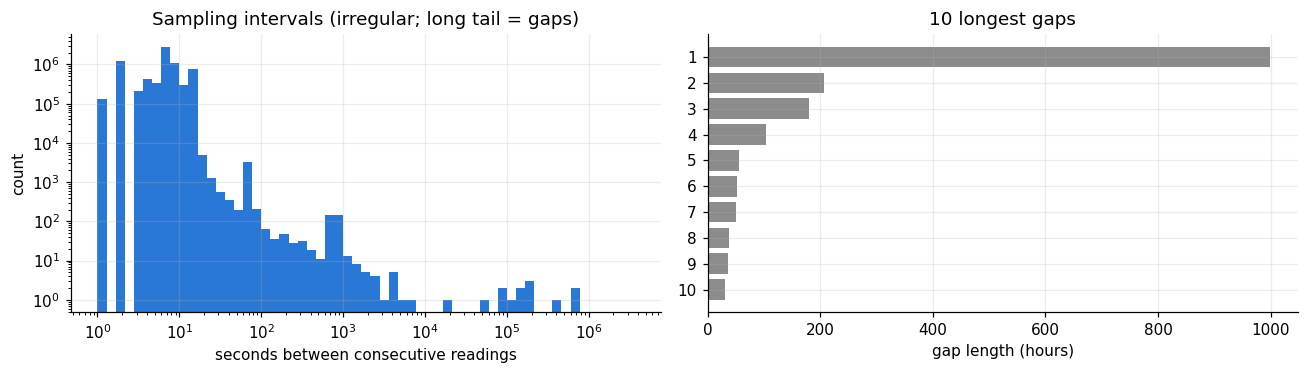

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
bins = np.logspace(0, np.log10(max(intervals.max(), 10)), 60)
ax[0].hist(intervals.clip(lower=1), bins=bins, color=C_TRUE)
ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('seconds between consecutive readings'); ax[0].set_ylabel('count')
ax[0].set_title('Sampling intervals (irregular; long tail = gaps)')
top = intervals.sort_values(ascending=False).head(10) / 3600
ax[1].barh(range(len(top))[::-1], top.values, color=C_AGG)
ax[1].set_yticks(range(len(top))[::-1]); ax[1].set_yticklabels([str(i) for i in range(1, len(top) + 1)])
ax[1].set_xlabel('gap length (hours)'); ax[1].set_title('10 longest gaps')
savefig('01_intervals.png')

**Interpretation:** most readings arrive every few seconds (median shown in the audit table), but the long tail shows real outages (hours–days) which must be *flagged*, not filled.

### 1.2 Cleaning pipeline
Documented rules:
1. **Drop** rows with unparseable timestamps.
2. **Sort** by timestamp (stable sort keeps original order among ties).
3. **De-duplicate** timestamps — rule: *keep the first reading* (the logger's first write; later duplicates are re-transmissions).
4. **Invalid values → NaN**: negative power, aggregate > 20 kW, single appliance > 4 kW (physically impossible for the supply / a 13 A plug).
5. **Resample to 1-minute means** (irregular ~8 s samples → regular grid).
6. **Fill short gaps** (≤ 5 consecutive missing minutes) by time interpolation — short enough that no appliance cycle can be invented.
7. **Flag longer gaps as outages** (`outage=True`) and leave them NaN; they are excluded from modelling.

In [11]:
def fill_short_gaps_count(s, max_len):
    # Interpolate only NaN runs of length <= max_len (never the start of a long gap).
    isna = s.isna()
    run_len = isna.groupby((~isna).cumsum()).transform('sum')
    short = isna & (run_len <= max_len)
    filled = s.interpolate(method='time', limit_area='inside')
    out = s.copy(); out[short] = filled[short]
    return out, int(short.sum())

def clean_refit(df, power_cols):
    log = {'rows_in': len(df)}
    df = df.dropna(subset=['ts'])
    log['dropped_bad_ts'] = log['rows_in'] - len(df)
    df = df.sort_values('ts', kind='mergesort')
    n = len(df); df = df.drop_duplicates('ts', keep='first'); log['dropped_duplicate_ts'] = n - len(df)
    for c in power_cols:
        lim = AGG_MAX_W if c == 'Aggregate' else APPL_MAX_W
        bad = (df[c] < 0) | (df[c] > lim)
        log[f'invalid_to_nan_{c}'] = int(bad.sum())
        df.loc[bad, c] = np.nan
    df = df.set_index('ts')
    m = df[power_cols].resample(RESAMPLE_RULE).mean()
    m['n_samples'] = df['Aggregate'].resample(RESAMPLE_RULE).count().astype('int16')
    log['minutes_grid'] = len(m)
    log['minutes_missing_before_fill'] = int(m['Aggregate'].isna().sum())
    for c in power_cols:
        m[c], nfill = fill_short_gaps_count(m[c], MAX_FILL_GAP_MIN)
        log[f'minutes_filled_{c}'] = nfill
    m['outage'] = m['Aggregate'].isna()
    log['minutes_outage'] = int(m['outage'].sum())
    log['outage_pct'] = round(100 * m['outage'].mean(), 2)
    m[power_cols] = m[power_cols].astype('float32')
    return m, log

t0 = time.time()
df1m, clean_log = clean_refit(raw, POWER_COLS)
print(f'Cleaning done in {time.time()-t0:.1f}s')
pd.Series(clean_log, name='value').to_frame()

Cleaning done in 6.0s


,value
rows_in,8518763.00
dropped_bad_ts,0.00
dropped_duplicate_ts,1211048.00
invalid_to_nan_Aggregate,104.00
invalid_to_nan_Appliance1,785.00
invalid_to_nan_Appliance2,35.00
invalid_to_nan_Appliance3,116.00
invalid_to_nan_Appliance4,1541.00
invalid_to_nan_Appliance5,191.00
invalid_to_nan_Appliance6,33.00


376 outage periods, total 1904.7 h, longest 998.4 h
              start  hours
2014-01-24 01:57:00  998.4
2015-05-10 23:37:00  207.6
2015-06-10 13:20:00  180.3
2015-04-03 01:44:00  104.6
2015-03-22 08:16:00   55.1


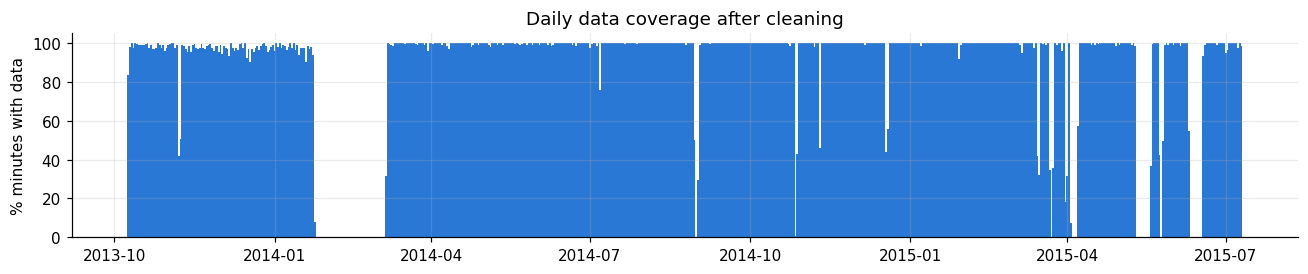

In [12]:
# Outage periods (runs of flagged minutes)
o = df1m['outage']
grp = (o != o.shift()).cumsum()
runs = o[o].groupby(grp[o]).agg(['size'])
runs['start'] = o[o].groupby(grp[o]).apply(lambda s: s.index.min()).values
runs = runs.rename(columns={'size': 'minutes'}).sort_values('minutes', ascending=False)
print(f'{len(runs)} outage periods, total {runs.minutes.sum()/60:.1f} h, longest {runs.minutes.max()/60 if len(runs) else 0:.1f} h')
print(runs.head(5).assign(hours=lambda d: (d.minutes/60).round(1))[['start', 'hours']].to_string(index=False))

cov = (~df1m['outage']).resample('1D').mean() * 100
fig, ax = plt.subplots(figsize=(12, 2.6))
ax.bar(cov.index.tz_convert(TZ), cov.values, width=1.0, color=C_TRUE)
ax.set_ylabel('% minutes with data'); ax.set_ylim(0, 105); ax.set_title('Daily data coverage after cleaning')
savefig('02_daily_coverage.png')

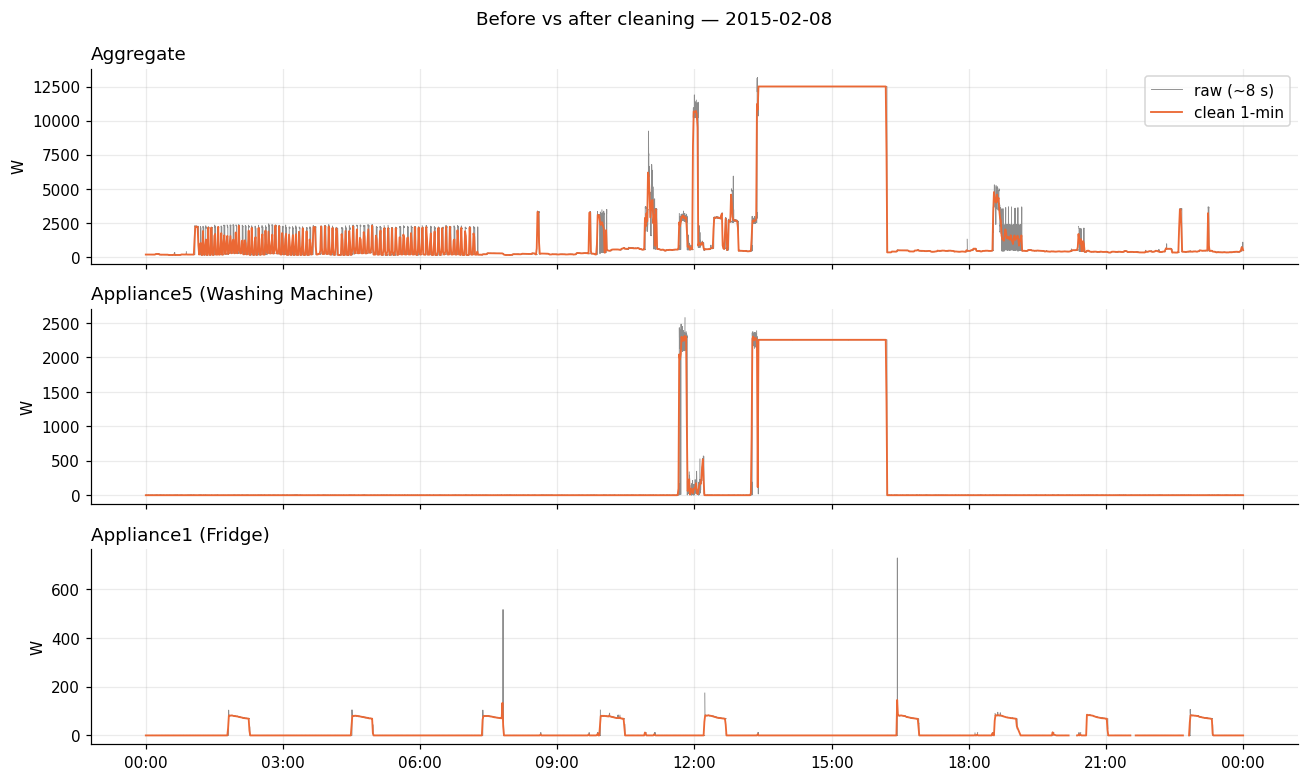

In [13]:
# Before / after plot: one day with washing-machine activity
day_energy = df1m[TARGET_COL].resample('1D').sum()
demo_day = day_energy.idxmax().tz_convert(TZ).normalize()
d0, d1 = demo_day.tz_convert('UTC'), (demo_day + pd.Timedelta(days=1)).tz_convert('UTC')
raw_day = raw[(raw.ts >= d0) & (raw.ts < d1)].sort_values('ts')
cl_day = df1m.loc[d0:d1]
show_cols = ['Aggregate', TARGET_COL] + OTHER_COLS[:1]

fig, axes = plt.subplots(len(show_cols), 1, figsize=(12, 2.4 * len(show_cols)), sharex=True)
for ax, c in zip(axes, show_cols):
    ax.plot(raw_day.ts.dt.tz_convert(TZ), raw_day[c], color=C_AGG, lw=0.6, label='raw (~8 s)')
    ax.plot(cl_day.index.tz_convert(TZ), cl_day[c], color=C_PRED, lw=1.2, label='clean 1-min')
    ax.set_ylabel('W'); ax.set_title(label(c), loc='left')
axes[0].legend(loc='upper right')
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz=TZ))
fig.suptitle(f'Before vs after cleaning — {demo_day.date()}')
savefig('03_before_after.png')

**Interpretation:** the 1-minute mean keeps the shape of every appliance event (heating plateau, spin bursts) while removing sample-rate irregularity; short dropouts are bridged, long ones stay empty.

In [14]:
df1m.to_parquet(os.path.join(OUT_DIR, 'house1_raw_cleaned_1min.parquet'))
json.dump({'files': [os.path.basename(p) for p in RAW_FILES], 'audit_raw': audit_before, 'cleaning_log': clean_log},
          open(os.path.join(OUT_DIR, 'part1_summary.json'), 'w'), indent=2, default=str)
PART1_MD = ("## Part 1 — raw House 1 (auto-generated)\n\nFiles: " + ', '.join(os.path.basename(p) for p in RAW_FILES) +
            "\n\n### Audit (before cleaning)\n" + pd.Series(audit_before, name='value').to_frame().to_markdown() +
            "\n\n### Cleaning log\n" + pd.Series(clean_log, name='value').to_frame().to_markdown() + "\n")
open(os.path.join(OUT_DIR, 'part1_for_DATA_md.md'), 'w').write(PART1_MD)
del raw, df1m; gc.collect()
print('Part 1 saved to', OUT_DIR)

Part 1 saved to /content/drive/MyDrive/refit_outputs/part1_raw_house1


# Part 2 — Washing-machine EDA (official clean data)

In [15]:
set_output('part2_3_multihouse')
t0 = time.time()
M, X, Y = {}, {}, {}
for h in ALL_H:
    M[h] = load_clean_house(CLEAN_FILES[h], WM_COL[h], max_days=MAX_DAYS_PER_HOUSE)
    X[h], Y[h] = prepare_house(M[h])
    print(f'House {h}: {len(M[h]):,} minutes, {len(Y[h]):,} usable, {time.time()-t0:.0f}s')
CYC = {h: detect_cycles(M[h]['wm'].where(~M[h]['outage'])) for h in HOUSES}

House 2: 525,601 minutes, 345,487 usable, 6s
House 3: 525,601 minutes, 456,181 usable, 14s
House 5: 525,600 minutes, 479,853 usable, 22s
House 6: 525,601 minutes, 451,359 usable, 28s
House 7: 525,601 minutes, 459,954 usable, 35s
House 10: 525,601 minutes, 473,832 usable, 43s
House 11: 525,601 minutes, 475,160 usable, 48s
House 13: 525,601 minutes, 401,815 usable, 53s
House 15: 519,488 minutes, 453,008 usable, 60s


In [16]:
rows = []
for h in HOUSES:
    m, c = M[h], CYC[h]
    ok = ~m['outage']
    o = m['outage']; grp = (o != o.shift()).cumsum(); runs = o[o].groupby(grp[o]).size()
    rows.append({'house': h, 'wm_column': WM_COL[h],
                 'from': m.index.min().tz_convert(TZ).date(), 'to': m.index.max().tz_convert(TZ).date(),
                 'days': round(len(m) / 1440, 1), 'missing_pct': round(100 * o.mean(), 2),
                 'outage_periods': len(runs), 'longest_outage_h': round(runs.max() / 60, 1) if len(runs) else 0,
                 'wm_off_pct': round(100 * (m.loc[ok, 'wm'] <= ON_THRESHOLD_W).mean(), 2),
                 'cycles': len(c), 'cycles_per_week': round(len(c) / (ok.sum() / 1440 / 7), 2),
                 'median_duration_min': c.duration_min.median(), 'median_energy_kwh': round(c.energy_kwh.median(), 3),
                 'median_peak_w': round(c.peak_w.median()), 'wm_share_of_energy_pct': round(100 * m.loc[ok, 'wm'].sum() / m.loc[ok, 'aggregate'].sum(), 2)})
quality = pd.DataFrame(rows).set_index('house')
quality.to_csv(os.path.join(OUT_DIR, 'house_quality.csv'))
show(quality)

        wm_column        from          to   days  missing_pct  outage_periods  \
house                                                                           
2      Appliance2  2013-09-17  2014-09-17  365.0        34.27             429   
3      Appliance6  2013-09-25  2014-09-25  365.0        13.21              91   
5      Appliance3  2013-09-26  2014-09-26  365.0         8.70             770   
6      Appliance2  2013-11-28  2014-11-28  365.0        14.13              97   
7      Appliance5  2013-11-01  2014-11-01  365.0        12.49              95   
10     Appliance5  2013-11-20  2014-11-20  365.0         9.85             777   

       longest_outage_h  wm_off_pct  cycles  cycles_per_week  \
house                                                          
2                1488.6       95.30     164             4.78   
3                 998.4       94.42     386             8.53   
5                  40.8       93.61     396             8.32   
6                 805.3       9

## 3. Washing-machine EDA
**Cycle rule in plain language:** the machine is *running* when its plug reads more than 20 W. Short pauses (up to 10 min, e.g. soaking) belong to the same wash. A wash must last at least 15 min and use at least 0.05 kWh — this ignores standby blips and door-open spikes.

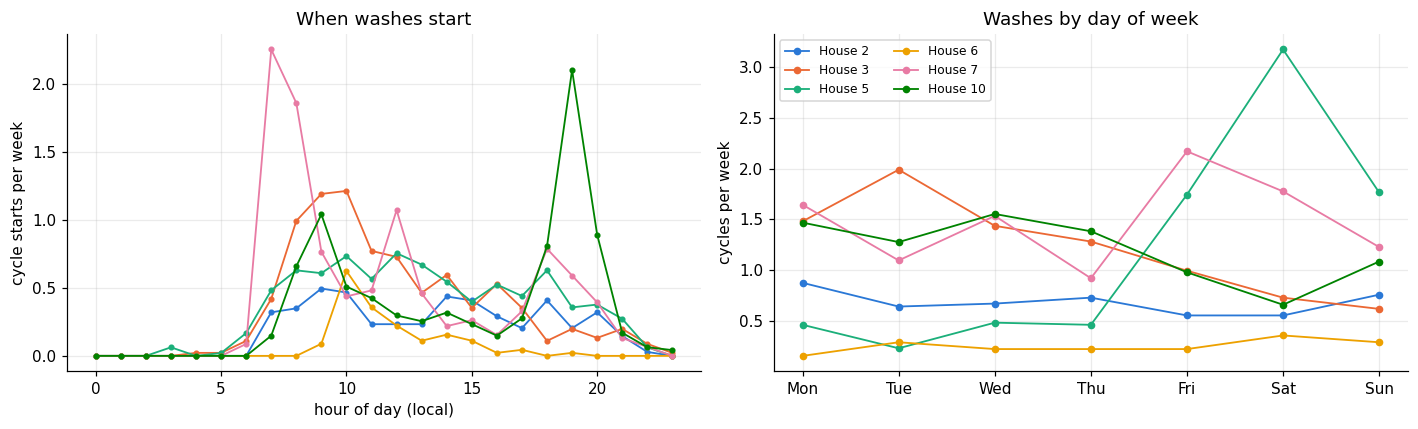

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, h in enumerate(HOUSES):
    st = CYC[h].start.dt.tz_convert(TZ)
    weeks = (~M[h]['outage']).sum() / 1440 / 7
    hh = st.dt.hour.value_counts().reindex(range(24), fill_value=0) / weeks
    dd = st.dt.dayofweek.value_counts().reindex(range(7), fill_value=0) / weeks
    ax[0].plot(range(24), hh.values, color=HOUSE_COLORS[k % 8], marker='o', ms=3, label=f'House {h}')
    ax[1].plot(range(7), dd.values, color=HOUSE_COLORS[k % 8], marker='o', ms=4, label=f'House {h}')
ax[0].set_xlabel('hour of day (local)'); ax[0].set_ylabel('cycle starts per week'); ax[0].set_title('When washes start')
ax[1].set_xticks(range(7)); ax[1].set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
ax[1].set_ylabel('cycles per week'); ax[1].set_title('Washes by day of week'); ax[1].legend(fontsize=8, ncol=2)
savefig('11_usage_hour_weekday.png')

**Interpretation:** compare the peaks — households differ in *when* they wash (morning vs evening, weekend-heavy). This is the load-shifting opportunity: evening-peak washes could move to off-peak hours.

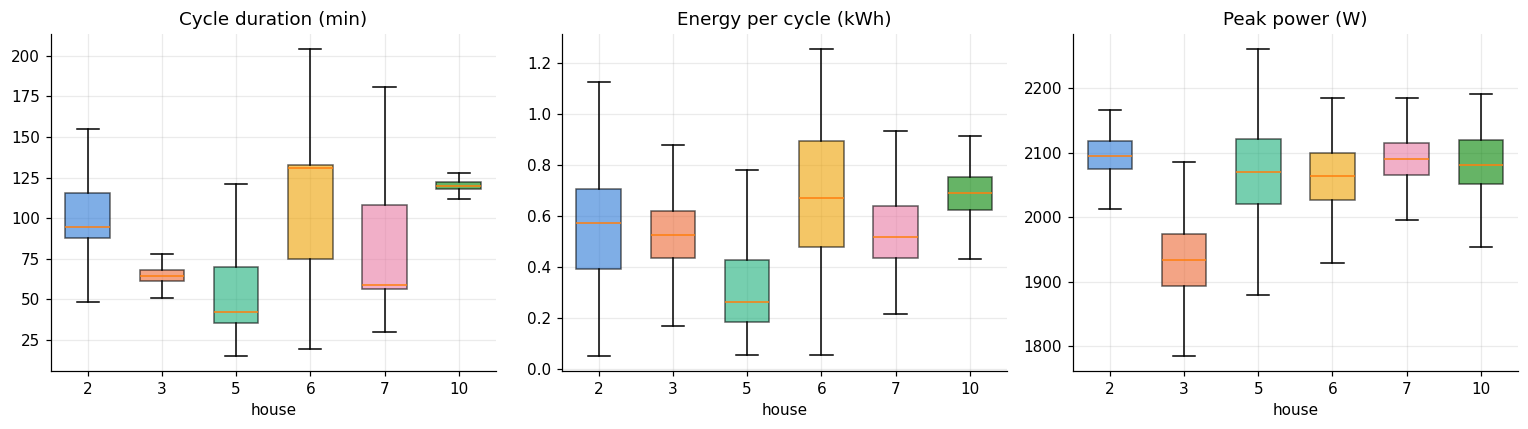

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, col, ttl in zip(ax, ['duration_min', 'energy_kwh', 'peak_w'], ['Cycle duration (min)', 'Energy per cycle (kWh)', 'Peak power (W)']):
    data = [CYC[h][col].values for h in HOUSES]
    bp = a.boxplot(data, patch_artist=True, showfliers=False, widths=0.6)
    a.set_xticks(range(1, len(HOUSES) + 1)); a.set_xticklabels([str(h) for h in HOUSES])
    for p_, k in zip(bp['boxes'], range(len(HOUSES))):
        p_.set_facecolor(HOUSE_COLORS[k % 8]); p_.set_alpha(0.6)
    a.set_title(ttl); a.set_xlabel('house')
savefig('12_cycle_comparison_across_houses.png')

**Interpretation:** energy and peak separate *hot* washes (≈2 kW heater, higher kWh) from *cold/quick* ones. Large differences between homes (machine model, programme habits) are exactly why a model trained on some homes may struggle on a new one.

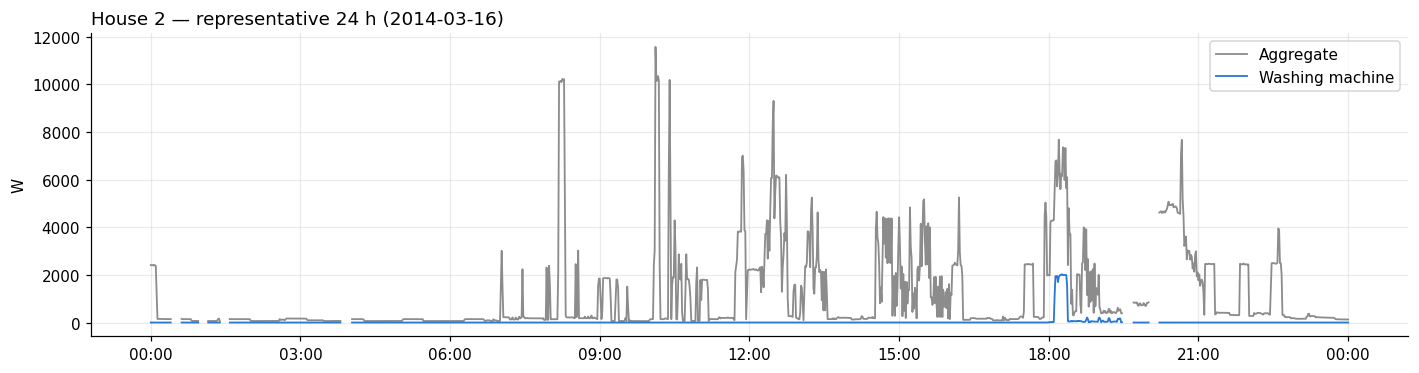

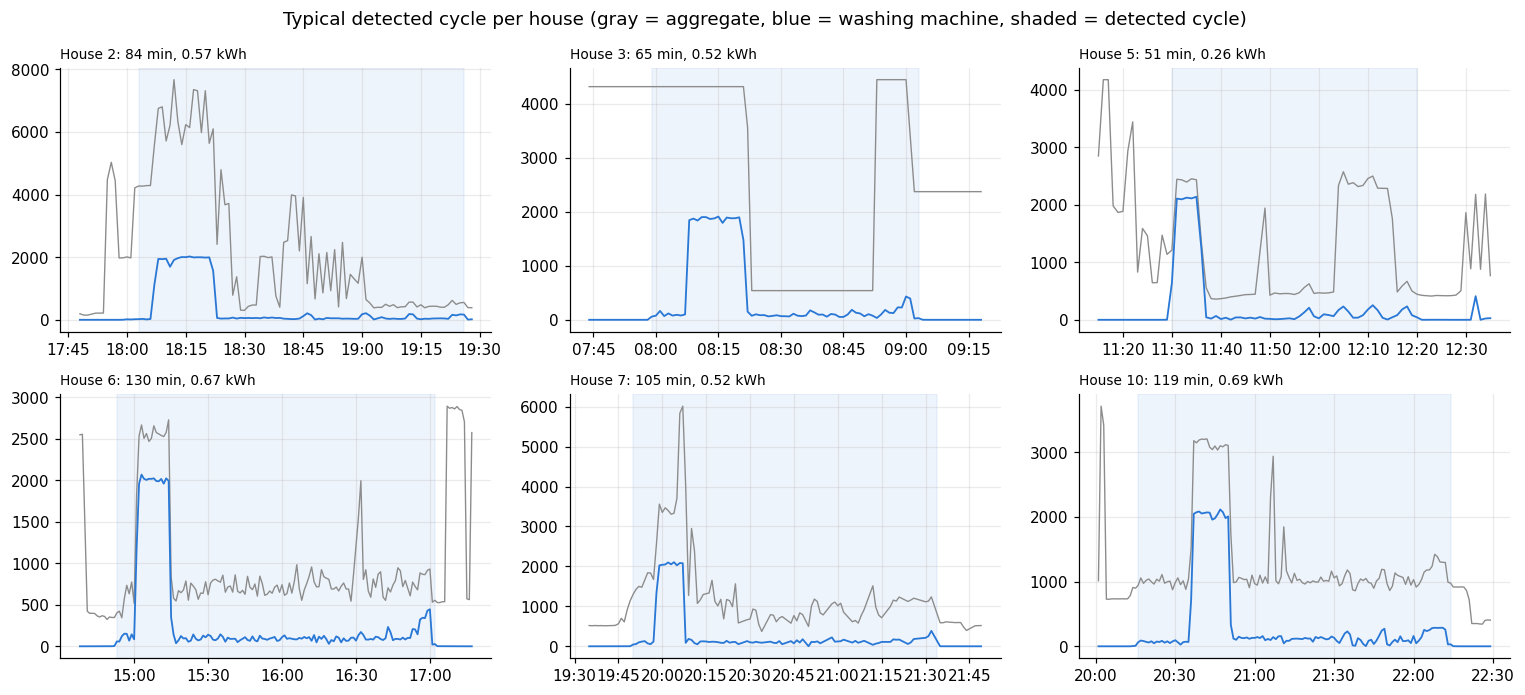

In [19]:
h0 = HOUSES[0]; c0 = CYC[h0]
rep = c0.iloc[(c0.energy_kwh - c0.energy_kwh.median()).abs().argmin()]
day0 = rep.start.tz_convert(TZ).normalize()
w = M[h0].loc[day0.tz_convert('UTC'):(day0 + pd.Timedelta(days=1)).tz_convert('UTC')]
fig, ax = plt.subplots(figsize=(13, 3.5))
ax.plot(w.index.tz_convert(TZ), w['aggregate'], color=C_AGG, label='Aggregate')
ax.plot(w.index.tz_convert(TZ), w['wm'], color=C_TRUE, label='Washing machine')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz=TZ)); ax.set_ylabel('W'); ax.legend()
ax.set_title(f'House {h0} — representative 24 h ({day0.date()})', loc='left')
savefig('13_representative_24h.png')

n = len(HOUSES); fig, axes = plt.subplots((n + 2) // 3, 3, figsize=(14, 3.2 * ((n + 2) // 3)))
for a, h in zip(np.ravel(axes), HOUSES):
    c = CYC[h]; r = c.iloc[(c.energy_kwh - c.energy_kwh.median()).abs().argmin()]
    z = M[h].loc[r.start - pd.Timedelta(minutes=15): r.end + pd.Timedelta(minutes=15)]
    a.plot(z.index.tz_convert(TZ), z['aggregate'], color=C_AGG, lw=0.9)
    a.plot(z.index.tz_convert(TZ), z['wm'], color=C_TRUE)
    a.axvspan(r.start.tz_convert(TZ), r.end.tz_convert(TZ), color=C_TRUE, alpha=0.08)
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz=TZ))
    a.set_title(f'House {h}: {r.duration_min} min, {r.energy_kwh:.2f} kWh', loc='left', fontsize=9)
for a in np.ravel(axes)[n:]: a.axis('off')
fig.suptitle('Typical detected cycle per house (gray = aggregate, blue = washing machine, shaded = detected cycle)')
savefig('14_detected_cycles_per_house.png')

**Interpretation:** the heater block (~2 kW) is the clearest signature; the drum/rinse phase (100–500 W) is small compared with fridge, lighting and cooking and is where the model must rely on context.

# Part 3 — Disaggregation model (leave-one-house-out)

### 3.1 Leave-one-house-out training
Per fold: feature selection (variance → correlation → permutation importance on the validation house) → models. Training minutes are **thinned** for speed: every minute near a wash or with extra load > 300 W (possible confounders) is kept, plus 15 % of quiet minutes re-weighted ×1/0.15 so the OFF prior is unchanged.

| Model | Idea |
|---|---|
| B0 Always-off | trivial baseline (machine is off > 95 % of the time) |
| B1 Hour-of-week profile | average WM power per weekday-hour of the training houses |
| A LightGBM regressor | one model predicting watts directly |
| B Gated LightGBM | P(ON) × watts-if-ON |
| B+ Gated LightGBM + cycle rule | EDA rule removes short false alarms, bridges pauses |
| C+ Gated CNN + cycle rule | deep Seq2Point-style comparison (GPU) |
| E Ensemble + cycle rule | average of B and C probabilities/watts |
| **S Selected on validation house** | per fold, the candidate (A, B, B+, C+, E) with the best F1 on the *validation* house — the final model; the test house plays no part in the choice |

Training houses per fold = the remaining test houses **plus `EXTRA_TRAIN` houses** that are never tested (more machines and households → better generalisation). Homes with a second washing appliance (washer-dryer / two machines) are excluded, because the second machine's signature would be labelled *off*.

In [20]:
CANDIDATES = ['A LightGBM regressor', 'B Gated LightGBM (soft)', 'B+ Gated LightGBM + cycle rule']
rows, PRED, FOLD_INFO = [], {}, []
os.makedirs(os.path.join(OUT_DIR, 'cache'), exist_ok=True)
for i, h_te in enumerate(HOUSES):
    h_va = HOUSES[(i + 1) % len(HOUSES)]
    h_tr = [h for h in HOUSES if h not in (h_te, h_va)] + EXTRA_TRAIN
    cache = os.path.join(OUT_DIR, 'cache', f"v2_test{h_te}_h{'-'.join(map(str, HOUSES))}_x{'-'.join(map(str, EXTRA_TRAIN))}_d{MAX_DAYS_PER_HOUSE}_cnn{int(RUN_CNN)}.pkl")
    if os.path.exists(cache):
        r_, P_, fi_ = pickle.load(open(cache, 'rb')); rows += r_; PRED[h_te] = P_; FOLD_INFO.append(fi_)
        print(f'test House {h_te}: loaded from cache'); continue
    t0 = time.time()
    thinned = [thin_training(X[h], Y[h]) for h in h_tr]
    X_tr = pd.concat([t[0] for t in thinned]); y_tr = pd.concat([t[1] for t in thinned]); w_tr = np.concatenate([t[2] for t in thinned])
    del thinned
    X_va, y_va, X_te, y_te = X[h_va], Y[h_va], X[h_te], Y[h_te]
    sel, info, _ = select_features(X_tr, y_tr, X_va, y_va)
    prof = pd.concat([Y[h] for h in h_tr]).pipe(lambda s: s.groupby(hour_of_week(s.index)).mean())
    P = {'B0 Always-off': np.zeros(len(y_te)),
         'B1 Hour-of-week profile': prof.reindex(hour_of_week(y_te.index)).fillna(0).to_numpy()}
    V = {}                                                     # validation-house predictions (for model selection)
    A = fit_regressor(X_tr[sel], y_tr, X_va[sel], y_va, w_tr)
    V['A LightGBM regressor'], P['A LightGBM regressor'] = A.predict(X_va[sel]), A.predict(X_te[sel])
    gate, reg = fit_gated(X_tr[sel], y_tr, X_va[sel], y_va, w_tr)
    pl_va, rl_va = gate.predict_proba(X_va[sel])[:, 1], np.clip(reg.predict(X_va[sel]), 0, None)
    pl_te, rl_te = gate.predict_proba(X_te[sel])[:, 1], np.clip(reg.predict(X_te[sel]), 0, None)
    tau_l = tune_tau(y_va, pl_va, rl_va, y_va.index)
    V['B Gated LightGBM (soft)'], P['B Gated LightGBM (soft)'] = pl_va * rl_va, pl_te * rl_te
    V['B+ Gated LightGBM + cycle rule'] = postprocess(pl_va, rl_va, y_va.index, tau_l)
    P['B+ Gated LightGBM + cycle rule'] = postprocess(pl_te, rl_te, y_te.index, tau_l)
    tau_c = tau_e = None
    if RUN_CNN:
        hds = {h: HouseData(M[h], Y[h].index, Y[h]) for h in [*h_tr, h_va, h_te]}
        net = train_cnn([hds[h] for h in h_tr], hds[h_va], epochs=CNN_EPOCHS, verbose=False)
        pc_va, rc_va = predict_cnn(net, hds[h_va]); pc_te, rc_te = predict_cnn(net, hds[h_te])
        tau_c = tune_tau(y_va, pc_va, rc_va, y_va.index)
        V['C+ Gated CNN + cycle rule'] = postprocess(pc_va, rc_va, y_va.index, tau_c)
        P['C+ Gated CNN + cycle rule'] = postprocess(pc_te, rc_te, y_te.index, tau_c)
        pe_va, re_va, pe_te, re_te = (pl_va + pc_va) / 2, (rl_va + rc_va) / 2, (pl_te + pc_te) / 2, (rl_te + rc_te) / 2
        tau_e = tune_tau(y_va, pe_va, re_va, y_va.index)
        V['E Ensemble LGBM+CNN + cycle rule'] = postprocess(pe_va, re_va, y_va.index, tau_e)
        P['E Ensemble LGBM+CNN + cycle rule'] = postprocess(pe_te, re_te, y_te.index, tau_e)
        del hds, net
    # S: pick the candidate with the best F1 on the VALIDATION house (test house never used)
    val_f1 = {k: f1_score(y_va > ON_THRESHOLD_W, np.asarray(v) > ON_THRESHOLD_W, zero_division=0) for k, v in V.items()}
    chosen = max(val_f1, key=val_f1.get)
    P['S Selected on validation house'] = P[chosen]
    for k, v in P.items():
        r = evaluate(y_te, v, y_te.index, k); r['test_house'] = h_te; rows.append(r)
    PRED[h_te] = P
    FOLD_INFO.append({'test': h_te, 'val': h_va, 'train': h_tr, 'train_minutes_after_thinning': len(y_tr), **info,
                      'tau_lgbm': tau_l, 'tau_cnn': tau_c, 'tau_ens': tau_e, 'val_F1': {k: round(v, 3) for k, v in val_f1.items()},
                      'chosen_on_val': chosen, 'selected': sel, 'seconds': round(time.time() - t0)})
    pickle.dump(([r for r in rows if r['test_house'] == h_te], P, FOLD_INFO[-1]), open(cache, 'wb'))
    print(f'test House {h_te} | val {h_va} | train {h_tr} | features {info["n_all"]}→{info["after_perm"]} | '
          f'chosen on val: {chosen} | test F1 {rows[-1]["F1"]:.3f} | {time.time()-t0:.0f}s')
    del X_tr, y_tr, w_tr; gc.collect()
RES = pd.DataFrame(rows)
RES.to_csv(os.path.join(OUT_DIR, 'loho_metrics_per_house.csv'), index=False)
pd.DataFrame(FOLD_INFO).to_csv(os.path.join(OUT_DIR, 'loho_folds.csv'), index=False)
print('\nModel chosen on the validation house per fold:', {f['test']: f['chosen_on_val'] for f in FOLD_INFO})

test House 2 | val 3 | train [5, 6, 7, 10, 11, 13, 15] | features 65→45 | chosen on val: E Ensemble LGBM+CNN + cycle rule | test F1 0.259 | 475s
test House 3 | val 5 | train [2, 6, 7, 10, 11, 13, 15] | features 65→39 | chosen on val: E Ensemble LGBM+CNN + cycle rule | test F1 0.568 | 325s
test House 5 | val 6 | train [2, 3, 7, 10, 11, 13, 15] | features 65→42 | chosen on val: E Ensemble LGBM+CNN + cycle rule | test F1 0.162 | 480s
test House 6 | val 7 | train [2, 3, 5, 10, 11, 13, 15] | features 65→44 | chosen on val: E Ensemble LGBM+CNN + cycle rule | test F1 0.741 | 686s
test House 7 | val 10 | train [2, 3, 5, 6, 11, 13, 15] | features 65→50 | chosen on val: E Ensemble LGBM+CNN + cycle rule | test F1 0.732 | 408s
test House 10 | val 2 | train [3, 5, 6, 7, 11, 13, 15] | features 65→49 | chosen on val: E Ensemble LGBM+CNN + cycle rule | test F1 0.543 | 491s

Model chosen on the validation house per fold: {2: 'E Ensemble LGBM+CNN + cycle rule', 3: 'E Ensemble LGBM+CNN + cycle rule', 5: 

### 3.2 Results (unseen-house test)

In [21]:
COLS = ['MAE_W', 'RMSE_W', 'MAE_on_W', 'precision', 'recall', 'F1', 'energy_err_pct', 'daily_MAE_kWh', 'cycle_recall', 'cycle_precision']
order = list(dict.fromkeys(RES.model))
mean, std = RES.groupby('model')[COLS].mean().loc[order], RES.groupby('model')[COLS].std().loc[order]
SUMMARY = mean.round(3).astype(str) + ' ± ' + std.round(3).astype(str)
SUMMARY.to_csv(os.path.join(OUT_DIR, 'loho_summary.csv'))
print('Mean ± std over', len(HOUSES), 'unseen test houses'); show(SUMMARY)
print('\nF1 per test house'); show(RES.pivot(index='test_house', columns='model', values='F1')[order].round(3))
print('\nDaily energy MAE (kWh/day) per test house'); show(RES.pivot(index='test_house', columns='model', values='daily_MAE_kWh')[order].round(3))

Mean ± std over 6 unseen test houses
                                            MAE_W            RMSE_W  \
model                                                                 
B0 Always-off                     24.778 ± 10.739  188.958 ± 48.237   
B1 Hour-of-week profile            41.449 ± 8.415  187.278 ± 46.689   
A LightGBM regressor              35.155 ± 10.955  160.549 ± 44.133   
B Gated LightGBM (soft)           37.855 ± 17.236  172.159 ± 52.125   
B+ Gated LightGBM + cycle rule    48.822 ± 34.079  204.657 ± 68.731   
C+ Gated CNN + cycle rule         34.805 ± 26.799  178.052 ± 74.447   
E Ensemble LGBM+CNN + cycle rule  30.245 ± 21.224  158.498 ± 59.189   
S Selected on validation house    30.245 ± 21.224  158.498 ± 59.189   

                                           MAE_on_W      precision  \
model                                                                
B0 Always-off                       404.468 ± 51.09      0.0 ± 0.0   
B1 Hour-of-week profile            374.486

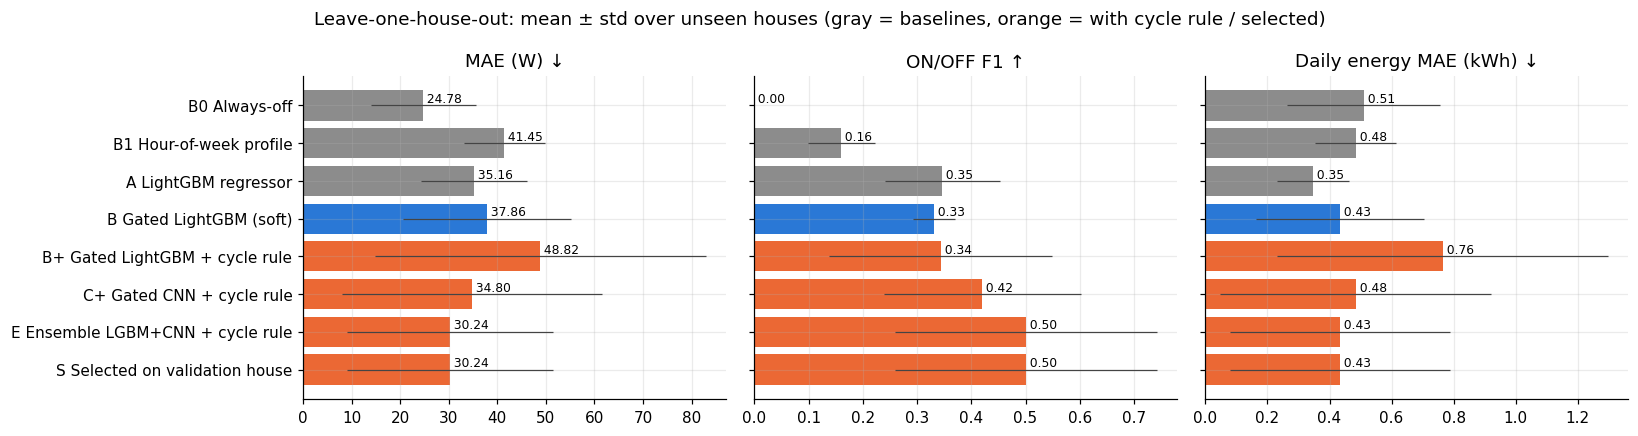

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col, ttl in zip(ax, ['MAE_W', 'F1', 'daily_MAE_kWh'], ['MAE (W) ↓', 'ON/OFF F1 ↑', 'Daily energy MAE (kWh) ↓']):
    mu, sd = mean[col].values[::-1], std[col].values[::-1]
    cols = [C_PRED if n_.startswith(('B+', 'C+', 'E ', 'S ')) else (C_TRUE if n_.startswith('B ') else C_AGG) for n_ in order][::-1]
    a.barh(order[::-1], mu, xerr=sd, color=cols, error_kw={'elinewidth': 0.8, 'ecolor': '#444'})
    for k, v in enumerate(mu): a.text(v, k, f' {v:.2f}', va='bottom', fontsize=8)
    a.set_title(ttl)
for a in ax[1:]: a.set_yticklabels([])
fig.suptitle('Leave-one-house-out: mean ± std over unseen houses (gray = baselines, orange = with cycle rule / selected)')
savefig('15_loho_ablation.png')

Final model: S Selected on validation house


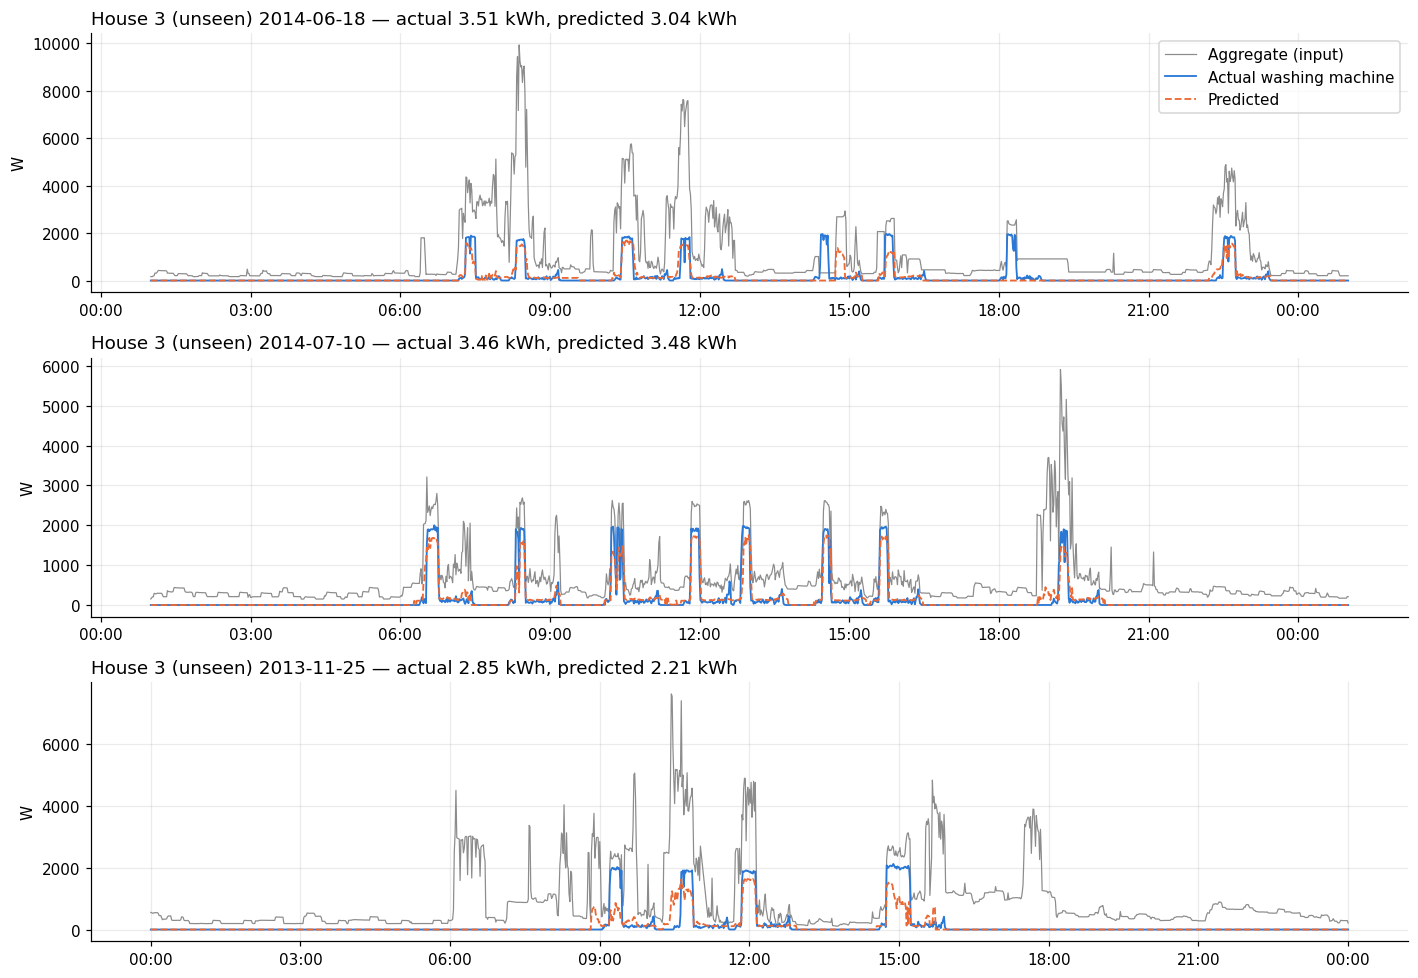

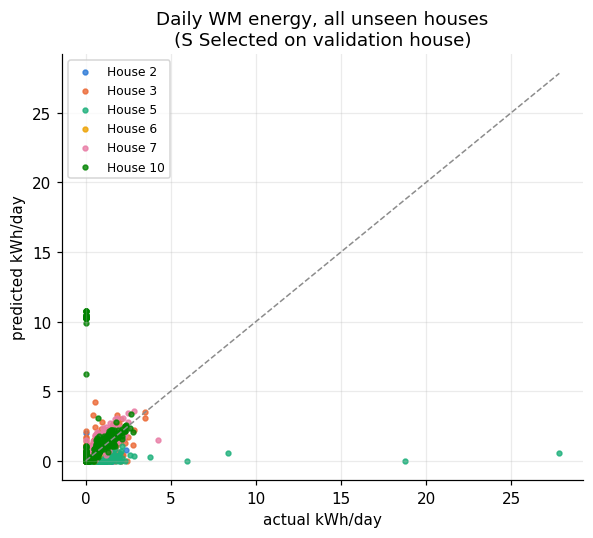

In [23]:
# Final model = per-fold choice made on the validation house only (never on test scores)
FINAL = 'S Selected on validation house'
print('Final model:', FINAL)
h_show = RES[RES.model == FINAL].sort_values('F1').test_house.iloc[len(HOUSES) // 2]   # median house, not the best
y_te = Y[h_show]; pred = pd.Series(PRED[h_show][FINAL], index=y_te.index)
days = y_te.resample('1D').sum().sort_values(ascending=False).index[:3]
fig, axes = plt.subplots(3, 1, figsize=(13, 9))
for a, d in zip(axes, days):
    sl = slice(d, d + pd.Timedelta(days=1)); t = y_te.loc[sl].index.tz_convert(TZ)
    a.plot(t, X[h_show].loc[sl, 'agg'], color=C_AGG, lw=0.8, label='Aggregate (input)')
    a.plot(t, y_te.loc[sl], color=C_TRUE, label='Actual washing machine')
    a.plot(t, pred.loc[sl], color=C_PRED, ls='--', label='Predicted')
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz=TZ)); a.set_ylabel('W')
    a.set_title(f'House {h_show} (unseen) {d.tz_convert(TZ).date()} — actual {y_te.loc[sl].sum()/60000:.2f} kWh, predicted {pred.loc[sl].sum()/60000:.2f} kWh', loc='left')
axes[0].legend(loc='upper right')
savefig('16_actual_vs_predicted_unseen_house.png')

fig, ax = plt.subplots(figsize=(5.5, 5))
mx = 0
for k, h in enumerate(HOUSES):
    dt_ = Y[h].resample('1D').sum() / 60000; dp_ = pd.Series(PRED[h][FINAL], index=Y[h].index).resample('1D').sum() / 60000
    ax.scatter(dt_, dp_, s=10, color=HOUSE_COLORS[k % 8], label=f'House {h}', alpha=0.8); mx = max(mx, dt_.max(), dp_.max())
ax.plot([0, mx], [0, mx], color=C_AGG, ls='--', lw=1); ax.set_xlabel('actual kWh/day'); ax.set_ylabel('predicted kWh/day')
ax.set_title(f'Daily WM energy, all unseen houses\n({FINAL})'); ax.legend(fontsize=8)
savefig('17_daily_energy_all_houses.png')

### 3.3 Failure analysis
Other sub-meter channels are loaded **only for diagnosis**: during false-alarm minutes, which appliances were running compared with normal OFF time (*lift* > 1 = over-represented).

In [24]:
fa_rows = []
for h in HOUSES:
    others = [c for c in NAMES[h] if c != WM_COL[h]]
    o = read_clean_columns(CLEAN_FILES[h], others).resample('1min').mean()
    o = o.reindex(Y[h].index)
    pred = PRED[h][FINAL]; fp = (pred > ON_THRESHOLD_W) & (Y[h].values <= ON_THRESHOLD_W); off = Y[h].values <= ON_THRESHOLD_W
    for c in others:
        on_c = (o[c] > ON_THRESHOLD_W).values
        r_fp, r_off = on_c[fp].mean() if fp.any() else np.nan, on_c[off].mean()
        fa_rows.append({'house': h, 'appliance': NAMES[h][c], 'on_during_false_alarm_pct': 100 * r_fp,
                        'on_during_off_pct': 100 * r_off, 'lift': r_fp / r_off if r_off else np.nan})
FA = pd.DataFrame(fa_rows)
FA.to_csv(os.path.join(OUT_DIR, 'failure_analysis.csv'), index=False)
show(FA.groupby('appliance')[['on_during_false_alarm_pct', 'on_during_off_pct', 'lift']].mean().sort_values('lift', ascending=False).round(2))

miss = []
for h in HOUSES:
    tc = detect_cycles(Y[h]); pc = detect_cycles(pd.Series(PRED[h][FINAL], index=Y[h].index))
    if len(tc):
        hit = ((pc.i0.values[None, :] < tc.i1.values[:, None]) & (pc.i1.values[None, :] > tc.i0.values[:, None])).any(1) if len(pc) else np.zeros(len(tc), bool)
        miss.append(tc.assign(detected=hit, house=h))
miss = pd.concat(miss)
print('\nDetected vs missed cycles (medians, all houses):')
show(miss.groupby('detected')[['duration_min', 'energy_kwh', 'peak_w']].median().round(2).assign(count=miss.groupby('detected').size()))

                  on_during_false_alarm_pct  on_during_off_pct  lift
appliance                                                           
Tumble Dryer                          26.19               3.68  6.97
Dishwasher                            32.57               6.75  4.92
Magimix(Blender)                      79.36              25.45  3.12
Kettle                                 2.97               1.13  2.84
Toaster                                2.25               5.54  2.20
Microwave                              3.21               1.61  2.01
Freezer(2)                             4.67               2.65  1.76
Television Site                       50.01              37.27  1.75
Desktop Computer                      57.99              38.95  1.49
K Mix                                  0.55               0.40  1.38
PGM Computer                          12.09               9.58  1.26
Fridge                                24.80              20.09  1.23
TV/Satellite                      

**Typical failure cases:**
1. **Overlapping heating appliances** — dishwasher and tumble dryer (often run right after a wash) draw the same ~2 kW blocks.
2. **Cold / quick washes** — no heater block; the 100–500 W drum phase hides under other loads → missed cycles (low peak in the table above).
3. **New household** — different machine/programmes; the per-house spread (± std) shows how much performance varies for a new customer.

# Z. Save outputs & markdown tables

In [25]:
import json
def to_md(df):
    try: return df.to_markdown()
    except ImportError: return '```\n' + df.to_string() + '\n```'
snippet = (f"Period: first {MAX_DAYS_PER_HOUSE} days of each house\n\n## Multi-house results (auto-generated)\n\nHouses: {HOUSES}; washing-machine columns: {WM_COL}\n\n"
           f"### Data quality\n{to_md(quality)}\n\n### Leave-one-house-out (mean ± std over unseen houses)\n{to_md(SUMMARY)}\n\n"
           f"### F1 per test house\n{to_md(RES.pivot(index='test_house', columns='model', values='F1')[order].round(3))}\n")
open(os.path.join(OUT_DIR, 'results_snippet_multihouse.md'), 'w').write(snippet)
json.dump({'houses': HOUSES, 'wm_col': WM_COL, 'final_model': FINAL, 'folds': FOLD_INFO},
          open(os.path.join(OUT_DIR, 'run_summary_multihouse.json'), 'w'), indent=2, default=str)
print('Saved to', OUT_DIR); print(sorted(os.listdir(OUT_DIR)))
import zipfile
zip_path = os.path.join(OUT_ROOT, 'refit_all_outputs.zip')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for root, _, files in os.walk(OUT_ROOT):
        if 'cache' in root: continue
        for f in files:
            if f.endswith(('.zip', '.parquet', '.pkl')): continue
            zf.write(os.path.join(root, f), os.path.relpath(os.path.join(root, f), OUT_ROOT))
print('\nEverything zipped →', zip_path)
print('\n' + '=' * 80 + '\nPASTE INTO RESULTS.md:\n' + '=' * 80 + '\n' + snippet)

Saved to /content/drive/MyDrive/refit_outputs/part2_3_multihouse
['cache', 'failure_analysis.csv', 'figures', 'house_quality.csv', 'loho_folds.csv', 'loho_metrics_per_house.csv', 'loho_summary.csv', 'results_snippet_multihouse.md', 'run_summary_multihouse.json']

Everything zipped → /content/drive/MyDrive/refit_outputs/refit_all_outputs.zip

PASTE INTO RESULTS.md:
Period: first 365 days of each house

## Multi-house results (auto-generated)

Houses: [2, 3, 5, 6, 7, 10]; washing-machine columns: {2: 'Appliance2', 3: 'Appliance6', 5: 'Appliance3', 6: 'Appliance2', 7: 'Appliance5', 10: 'Appliance5', 11: 'Appliance3', 13: 'Appliance3', 15: 'Appliance3'}

### Data quality
|   house | wm_column   | from       | to         |   days |   missing_pct |   outage_periods |   longest_outage_h |   wm_off_pct |   cycles |   cycles_per_week |   median_duration_min |   median_energy_kwh |   median_peak_w |   wm_share_of_energy_pct |
|--------:|:------------|:-----------|:-----------|-------:|----------